# Projeto Machine Learning — Predição de Preço de Imóveis

**Modelo A:** Regressão Linear Múltipla
**Modelo B:** KNN de Regressão  
**Alvo:** `price` (valor do imóvel)  
**Dataset:** `house_price_50k.csv`

Objetivo: treinar dois modelos clássicos de Machine Learning e comparar o desempenho.

## 1. Importação das bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

random_seed = 42

## 2. Carregamento dos dados

In [2]:
df = pd.read_csv('house_price_50k.csv')
print('Formato (linhas, colunas):', df.shape)
df.head()

Formato (linhas, colunas): (50000, 19)


,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level,price
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,premium,low,5.952493e+05
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,low,low,1.571208e+06
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,premium,mid,1.379943e+06
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,medium,low,4.367819e+05
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,low,mid,1.792425e+06


## 3. Análise Exploratória de Dados (EDA)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   area                  50000 non-null  int64  
 1   bedrooms              50000 non-null  int64  
 2   bathrooms             50000 non-null  int64  
 3   floors                50000 non-null  int64  
 4   age                   50000 non-null  int64  
 5   distance              50000 non-null  int64  
 6   garage                50000 non-null  int64  
 7   parking               50000 non-null  int64  
 8   garden                50000 non-null  int64  
 9   security              50000 non-null  int64  
 10  school_nearby         50000 non-null  int64  
 11  hospital_nearby       50000 non-null  int64  
 12  shopping_mall_nearby  50000 non-null  int64  
 13  public_transport      50000 non-null  int64  
 14  crime_rate            50000 non-null  float64
 15  population_density 

In [4]:
df.describe()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,price
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,5.000000e+04
mean,2752.970540,3.496040,2.498040,1.997060,19.573740,14.968700,0.500540,0.497300,0.500280,0.496220,0.501100,0.498320,0.498320,0.500040,5.006444,5065.94598,1.030261e+06
std,1297.148134,1.712146,1.117704,0.815368,11.552502,8.363714,0.500005,0.499998,0.500005,0.499991,0.500004,0.500002,0.500002,0.500005,2.876776,2864.34322,4.580199e+05
min,500.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000311,100.00000,9.090069e+04
25%,1630.000000,2.000000,1.000000,1.000000,10.000000,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.523018,2575.00000,6.357375e+05
50%,2756.000000,3.000000,2.000000,2.000000,20.000000,15.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,5.022946,5060.50000,1.031763e+06
75%,3872.000000,5.000000,3.000000,3.000000,30.000000,22.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.479632,7543.00000,1.423102e+06
max,4999.000000,6.000000,4.000000,3.000000,39.000000,29.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,9.999869,9999.00000,1.996474e+06


In [5]:
print('Valores ausentes por coluna:')
print(df.isnull().sum())

Valores ausentes por coluna:
area                    0
bedrooms                0
bathrooms               0
floors                  0
age                     0
distance                0
garage                  0
parking                 0
garden                  0
security                0
school_nearby           0
hospital_nearby         0
shopping_mall_nearby    0
public_transport        0
crime_rate              0
population_density      0
location                0
income_level            0
price                   0
dtype: int64


## 3.1. Diagnóstico de Outliers

In [6]:
colunas_num = df.select_dtypes(include=[np.number]).columns

diag_outliers = []

for c in colunas_num:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    n_outliers = 0
    for valor in df[c]:
        if valor < limite_inferior or valor > limite_superior:
            n_outliers = n_outliers + 1

    diag_outliers.append({
        'campo': c,
        'limite_inferior': round(limite_inferior, 2),
        'limite_superior': round(limite_superior, 2),
        'n_outliers': n_outliers,
    })

tabela_outliers = pd.DataFrame(diag_outliers)
tabela_outliers

,campo,limite_inferior,limite_superior,n_outliers
0,area,-1733.00,7235.00,0
1,bedrooms,-2.50,9.50,0
2,bathrooms,-2.00,6.00,0
3,floors,-2.00,6.00,0
4,age,-20.00,60.00,0
5,distance,-13.00,43.00,0
6,garage,-1.50,2.50,0
7,parking,-1.50,2.50,0
8,garden,-1.50,2.50,0
9,security,-1.50,2.50,0


## 3.2. Contagem de Classes e Verificação de Desbalanceamento

In [7]:
def analisar_balanceamento(coluna):
    contagem = df[coluna].value_counts()
    porcentagem = (contagem / len(df) * 100).round(2)
    tabela = pd.DataFrame({'contagem': contagem, 'porcentagem(%)': porcentagem})
    return tabela

In [8]:
analisar_balanceamento('location')

,contagem,porcentagem(%)
location,,
medium,16756,33.51
low,16642,33.28
premium,16602,33.20


In [9]:
analisar_balanceamento('income_level')

,contagem,porcentagem(%)
income_level,,
mid,16738,33.48
low,16651,33.30
high,16611,33.22


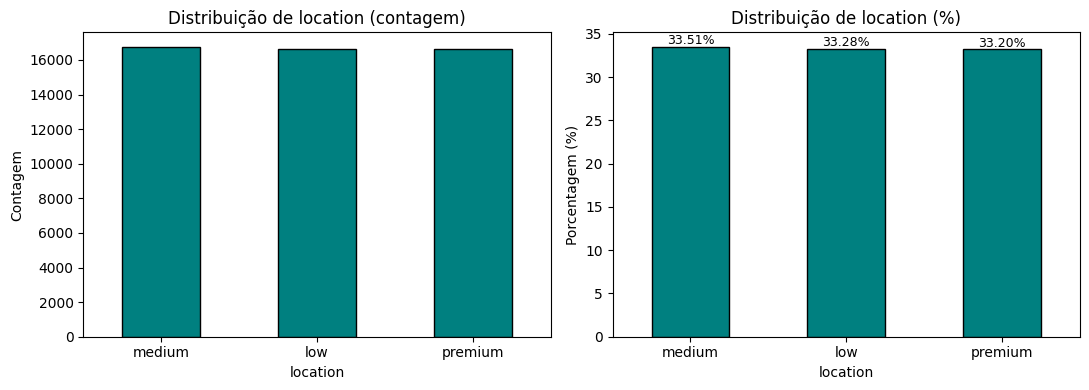

In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))

df['location'].value_counts().plot(kind='bar', ax=eixos[0], color='teal', edgecolor='black')
eixos[0].set_title('Distribuição de location (contagem)')
eixos[0].set_ylabel('Contagem')
eixos[0].tick_params(axis='x', rotation=0)

pct_location = df['location'].value_counts(normalize=True) * 100
pct_location.plot(kind='bar', ax=eixos[1], color='teal', edgecolor='black')
eixos[1].set_title('Distribuição de location (%)')
eixos[1].set_ylabel('Porcentagem (%)')
eixos[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(pct_location):
    eixos[1].text(i, v + 0.3, f'{v:.2f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

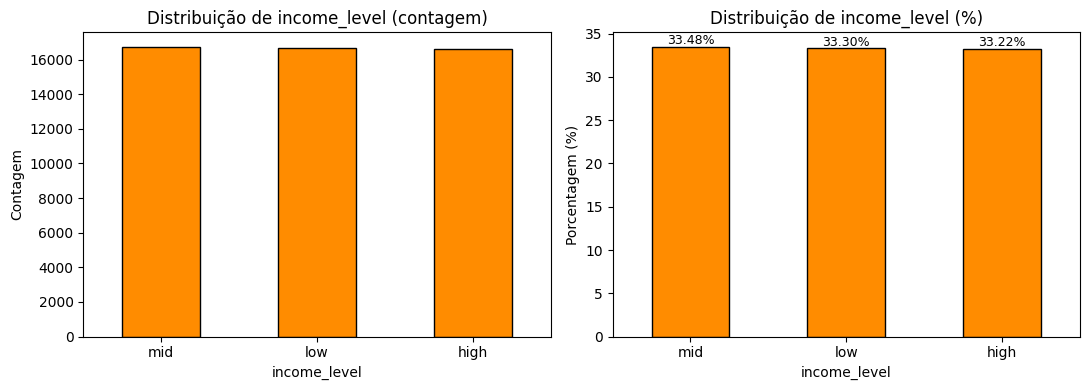

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))

df['income_level'].value_counts().plot(kind='bar', ax=eixos[0], color='darkorange', edgecolor='black')
eixos[0].set_title('Distribuição de income_level (contagem)')
eixos[0].set_ylabel('Contagem')
eixos[0].tick_params(axis='x', rotation=0)

pct_income_level = df['income_level'].value_counts(normalize=True) * 100
pct_income_level.plot(kind='bar', ax=eixos[1], color='darkorange', edgecolor='black')
eixos[1].set_title('Distribuição de income_level (%)')
eixos[1].set_ylabel('Porcentagem (%)')
eixos[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(pct_income_level):
    eixos[1].text(i, v + 0.3, f'{v:.2f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 3.3. Histograma da variável alvo

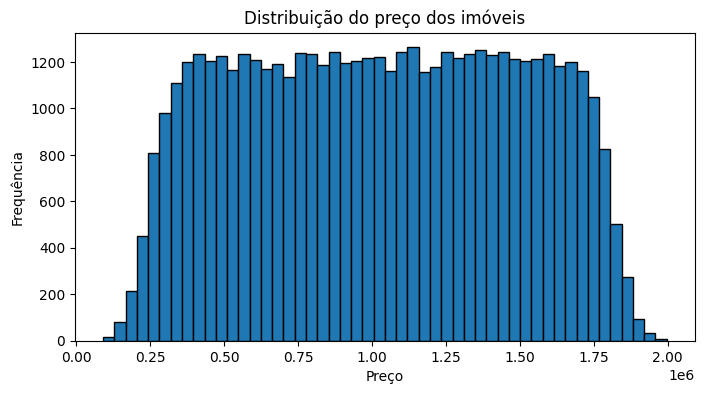

In [13]:
plt.figure(figsize=(8, 4))
plt.hist(df['price'], bins=50, edgecolor='black')
plt.title('Distribuição do preço dos imóveis')
plt.xlabel('Preço')
plt.ylabel('Frequência')
plt.show()

## 4. Pré-processamento e Feature Engineering

In [14]:
X = df.drop(columns=['price']).copy()
y = df['price']

ordem_location = ['low', 'medium', 'premium']
ordem_income = ['low', 'mid', 'high']

codificador = OrdinalEncoder(categories=[ordem_location, ordem_income])
X[['location', 'income_level']] = codificador.fit_transform(X[['location', 'income_level']])

X.head()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,school_nearby,hospital_nearby,shopping_mall_nearby,public_transport,crime_rate,population_density,location,income_level
0,1360,6,2,2,9,10,0,0,1,0,1,0,1,0,6.939333,7242,2.0,0.0
1,4272,5,2,3,24,8,1,0,0,1,1,1,1,0,0.400918,7729,0.0,0.0
2,3592,1,4,3,4,20,0,1,1,1,0,1,0,1,6.292386,1081,2.0,1.0
3,966,5,2,2,6,14,1,0,0,0,0,1,1,0,8.964112,8912,1.0,0.0
4,4926,4,3,1,18,9,0,0,0,0,1,0,1,1,2.843309,8146,0.0,1.0


In [15]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=random_seed
)

print('Tamanho do treino:', X_treino.shape)
print('Tamanho do teste :', X_teste.shape)

Tamanho do treino: (40000, 18)
Tamanho do teste : (10000, 18)


In [16]:
escalonador = StandardScaler()
X_treino_esc = escalonador.fit_transform(X_treino)
X_teste_esc = escalonador.transform(X_teste)

## 5. Modelo A — Regressão Linear Múltipla

In [17]:
modelo_linear = LinearRegression()
modelo_linear.fit(X_treino_esc, y_treino)
y_pred_linear = modelo_linear.predict(X_teste_esc)

mae_linear = mean_absolute_error(y_teste, y_pred_linear)
mse_linear = mean_squared_error(y_teste, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_teste, y_pred_linear)

print(f'MAE : {mae_linear:,.2f}')
print(f'MSE : {mse_linear:,.2f}')
print(f'RMSE: {rmse_linear:,.2f}')
print(f'R²  : {r2_linear:.4f}')

MAE : 16,096.30
MSE : 403,839,523.11
RMSE: 20,095.76
R²  : 0.9981


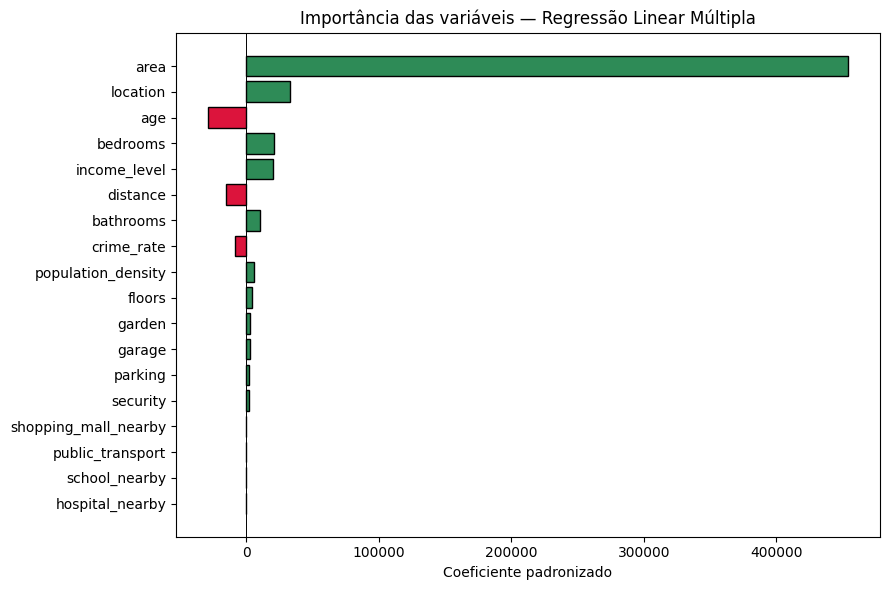

In [18]:
importancia_linear = pd.DataFrame({
    'variavel': X.columns,
    'coeficiente': modelo_linear.coef_
}).sort_values(by='coeficiente', key=abs, ascending=True)

cores = ['crimson' if v < 0 else 'seagreen' for v in importancia_linear['coeficiente']]

plt.figure(figsize=(9, 6))
plt.barh(importancia_linear['variavel'], importancia_linear['coeficiente'],
         color=cores, edgecolor='black')
plt.axvline(0, color='black', linewidth=0.7)
plt.title('Importância das variáveis — Regressão Linear Múltipla')
plt.xlabel('Coeficiente padronizado')
plt.tight_layout()
plt.show()

## 6. Modelo B — KNN de Regressão

In [19]:
# Testa valores ímpares de k até 100
bestK = 1
bestR2 = float('-inf')

tentativas_sem_melhora = 0
limite_sem_melhora = 5

for k in range(1, 100, 2):

    modelo_temp = KNeighborsRegressor(n_neighbors=k)
    modelo_temp.fit(X_treino_esc, y_treino)

    pred_temp = modelo_temp.predict(X_teste_esc)
    r2_temp = r2_score(y_teste, pred_temp)

    rmse_temp = np.sqrt(mean_squared_error(y_teste, pred_temp))

    # Verifica se o R² melhorou
    if r2_temp > bestR2:
        bestK = k
        bestR2 = r2_temp
        tentativas_sem_melhora = 0
    else:
        tentativas_sem_melhora += 1

    print(
        f'k={k:2d} | R²={r2_temp:.4f} | '
        f'RMSE={rmse_temp:,.2f} | '
        f'Sem melhora: {tentativas_sem_melhora}'
    )

    # Interrompe após 5 valores sem melhora
    if tentativas_sem_melhora >= limite_sem_melhora:
        print('\nParando: 5 valores consecutivos sem melhora.')
        break

print(f'\nMelhor k encontrado: {bestK}')
print(f'Melhor R²: {bestR2:.4f}')

k= 1 | R²=0.5509 | RMSE=307,581.33 | Sem melhora: 0
k= 3 | R²=0.7687 | RMSE=220,710.52 | Sem melhora: 0
k= 5 | R²=0.8090 | RMSE=200,595.06 | Sem melhora: 0
k= 7 | R²=0.8248 | RMSE=192,117.78 | Sem melhora: 0
k= 9 | R²=0.8316 | RMSE=188,324.15 | Sem melhora: 0
k=11 | R²=0.8336 | RMSE=187,201.62 | Sem melhora: 0
k=13 | R²=0.8358 | RMSE=186,000.69 | Sem melhora: 0
k=15 | R²=0.8363 | RMSE=185,712.04 | Sem melhora: 0
k=17 | R²=0.8373 | RMSE=185,099.75 | Sem melhora: 0
k=19 | R²=0.8374 | RMSE=185,078.53 | Sem melhora: 0
k=21 | R²=0.8370 | RMSE=185,303.83 | Sem melhora: 1
k=23 | R²=0.8368 | RMSE=185,402.55 | Sem melhora: 2
k=25 | R²=0.8360 | RMSE=185,846.71 | Sem melhora: 3
k=27 | R²=0.8355 | RMSE=186,168.91 | Sem melhora: 4
k=29 | R²=0.8349 | RMSE=186,464.34 | Sem melhora: 5

Parando: 5 valores consecutivos sem melhora.

Melhor k encontrado: 19
Melhor R²: 0.8374


In [21]:
modelo_knn = KNeighborsRegressor(n_neighbors=bestK)
modelo_knn.fit(X_treino_esc, y_treino)
y_pred_knn = modelo_knn.predict(X_teste_esc)

mae_knn = mean_absolute_error(y_teste, y_pred_knn)
mse_knn = mean_squared_error(y_teste, y_pred_knn)
rmse_knn = np.sqrt(mse_knn)
r2_knn = r2_score(y_teste, y_pred_knn)

print(f'MAE : {mae_knn:,.2f}')
print(f'MSE : {mse_knn:,.2f}')
print(f'RMSE: {rmse_knn:,.2f}')
print(f'R²  : {r2_knn:.4f}')

MAE : 153,175.10
MSE : 34,254,063,432.22
RMSE: 185,078.53
R²  : 0.8374


## 7. Comparação dos Modelos

In [22]:
resultados = pd.DataFrame({
    'Modelo': ['Regressão Linear Múltipla',  'KNN'],
    'MAE':  [mae_linear, mae_knn],
    'MSE':  [mse_linear, mse_knn],
    'RMSE': [rmse_linear, rmse_knn],
    'R²':   [r2_linear, r2_knn],
})
resultados

,Modelo,MAE,MSE,RMSE,R²
0,Regressão Linear Múltipla,16096.302529,4.038395e+08,20095.758834,0.998083
1,KNN,153175.101101,3.425406e+10,185078.533148,0.837384


### Gráfico Real vs Previsto

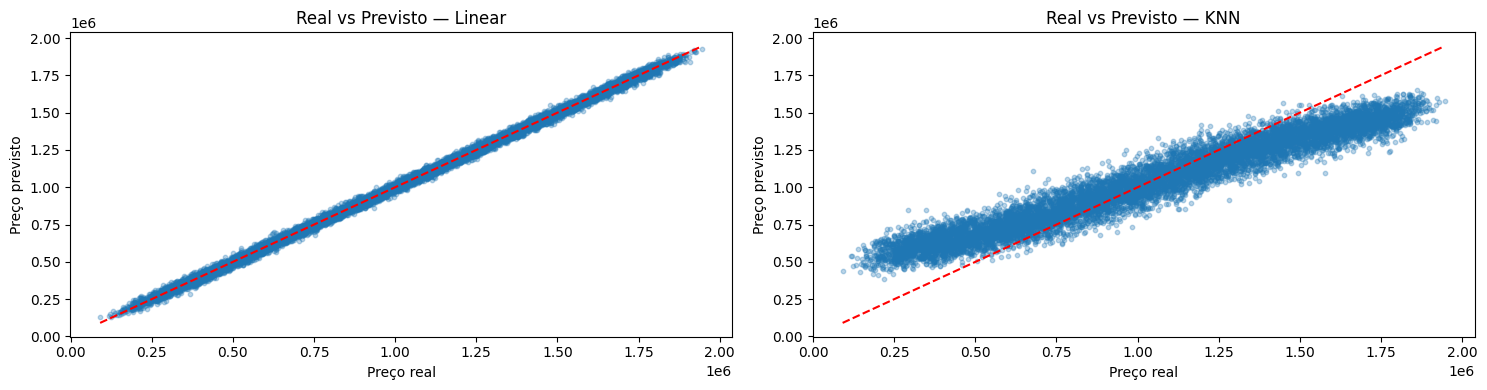

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 4))
for eixo, (nome, pred) in zip(
    eixos,
    [('Linear', y_pred_linear),  ('KNN', y_pred_knn)]
):
    eixo.scatter(y_teste, pred, alpha=0.3, s=10)
    eixo.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], 'r--')
    eixo.set_xlabel('Preço real')
    eixo.set_ylabel('Preço previsto')
    eixo.set_title(f'Real vs Previsto — {nome}')
plt.tight_layout()
plt.show()